# 01 — Data acquisition & EDA
UCI Heart Disease (Cleveland). 303 patients, 13 features, `num` 0-4 reduced to a binary target.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.width", 140)

In [2]:
from src.data import download, load_raw, clean
from src.config import NUMERIC_FEATURES, CATEGORICAL_FEATURES, TARGET
download()
raw = load_raw()
raw.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


### Missing values in the raw file
`?` is the missing marker; only `ca` and `thal` have gaps.

In [3]:
raw.isna().sum()[lambda s: s > 0]

ca      4
thal    2
dtype: int64

In [4]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


In [5]:
df = clean(raw)
print(df.shape, '| missing after cleaning:', df.isna().sum().sum())
df[TARGET].value_counts(normalize=True).round(3)

(303, 14) | missing after cleaning: 0


target
0    0.541
1    0.459
Name: proportion, dtype: float64

### Class balance
The split is close to even (54% / 46%), so no resampling is needed. Metrics still include precision, recall and ROC-AUC.

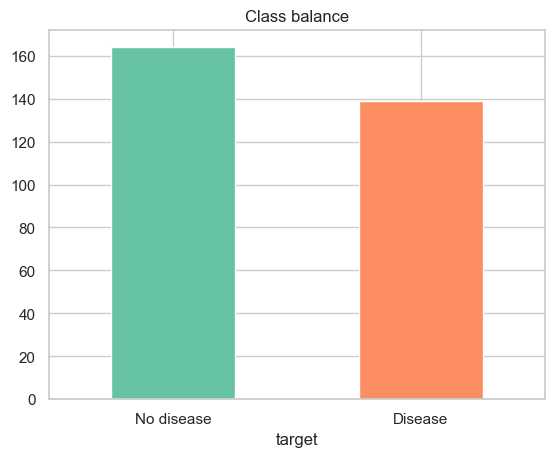

In [6]:
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='whitegrid')
ax = df[TARGET].map({0:'No disease',1:'Disease'}).value_counts().plot.bar(color=['#66c2a5','#fc8d62'], rot=0)
ax.set_title('Class balance'); plt.show()

### Numeric distributions by target

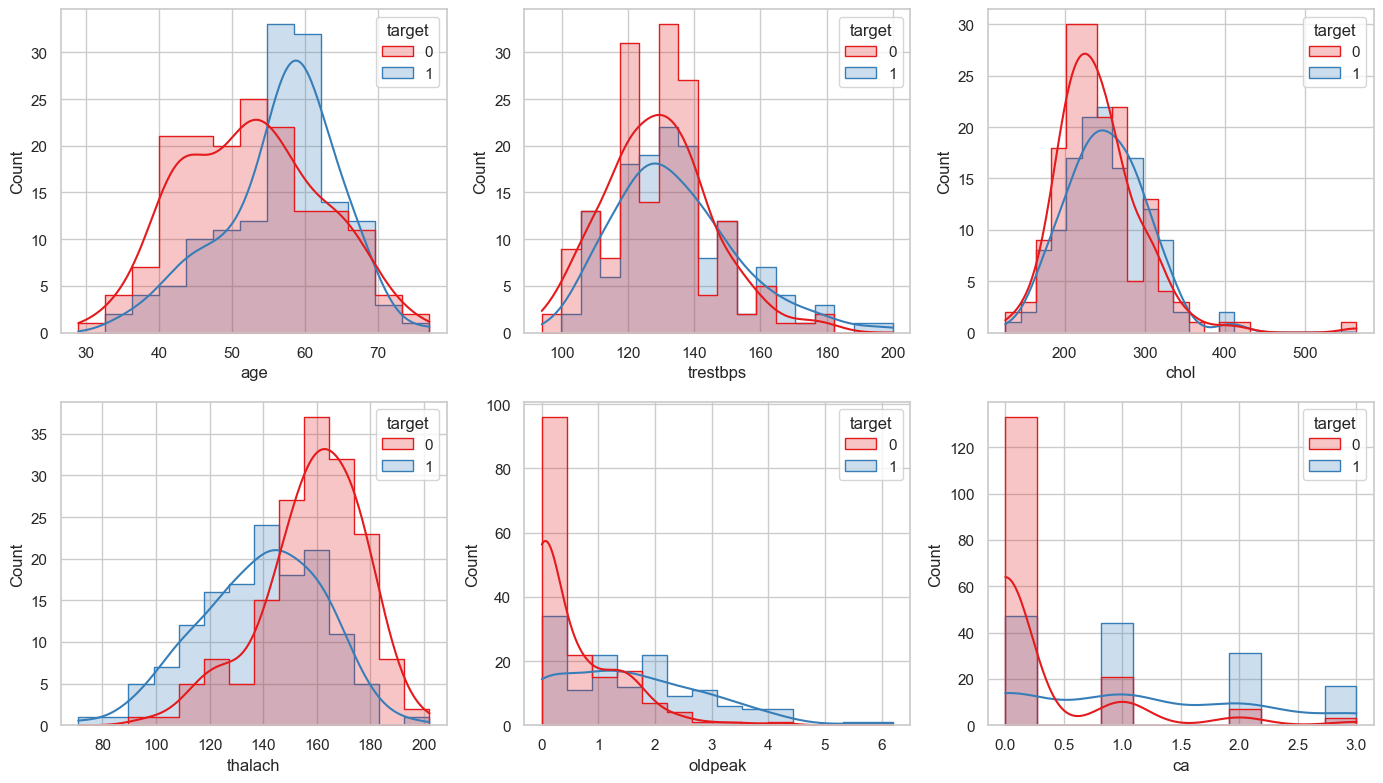

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, c in zip(axes.flat, NUMERIC_FEATURES):
    sns.histplot(data=df, x=c, hue=TARGET, kde=True, element='step', palette='Set1', ax=ax)
plt.tight_layout(); plt.show()

### Categorical features: disease rate per level

In [8]:
pd.concat({c: df.groupby(c)[TARGET].mean().round(2) for c in CATEGORICAL_FEATURES}).to_frame('disease_rate')

disease_rate
sex     0          0.26
        1          0.55
cp      1          0.30
        2          0.18
        3          0.21
        4          0.73
fbs     0          0.45
        1          0.49
restecg 0          0.37
        1          0.75
        2          0.54
exang   0          0.31
        1          0.77
slope   1          0.25
        2          0.65
        3          0.57
thal    3          0.23
        6          0.67
        7          0.76

### Correlation heatmap

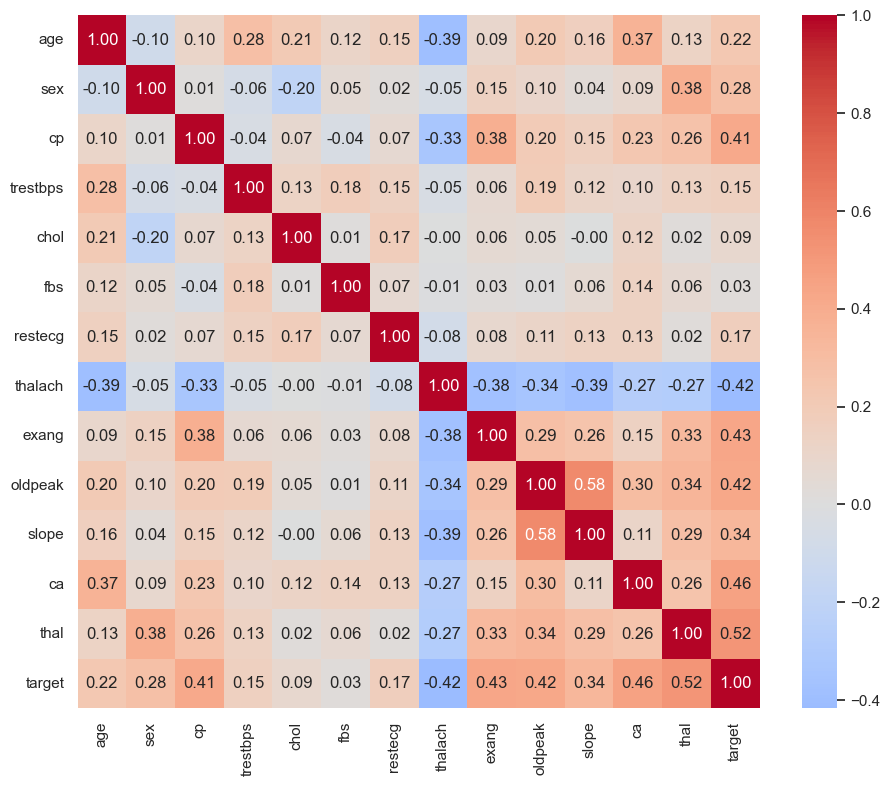

In [9]:
plt.figure(figsize=(11, 9))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.show()

In [10]:
df.corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3)

thal        0.522
ca          0.460
exang       0.432
oldpeak     0.425
thalach    -0.417
cp          0.414
slope       0.339
sex         0.277
age         0.223
restecg     0.169
trestbps    0.151
chol        0.085
fbs         0.025
Name: target, dtype: float64

### Takeaways
- The strongest signals are `thal`, `ca`, `cp`, `exang`, `oldpeak` and `thalach` (lower max heart rate means higher risk).
- `cp`, `thal`, `restecg` and `slope` are nominal codes, so they are one-hot encoded instead of treated as ordinal.
- `chol` and `fbs` are only weakly related to the target.

In [11]:
from src.config import CLEAN_FILE
df.to_csv(CLEAN_FILE, index=False); CLEAN_FILE

WindowsPath('D:/mlops/data/processed/heart_clean.csv')